<h1>Cek Data</h1>

In [4]:
import pandas as pd 
import numpy as np 
from scipy import stats

In [5]:
df= pd.read_csv("data_prototipe.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   No        20 non-null     int64  
 1   Data ke   20 non-null     int64  
 2   Aplikasi  20 non-null     str    
 3   Rating    20 non-null     float64
 4   Type      20 non-null     str    
dtypes: float64(1), int64(2), str(2)
memory usage: 932.0 bytes


<h3>Ringkasan Data</h3>

In [6]:
ringkasan = df.groupby("Type")["Rating"].agg(["count", "mean", "std"])
ringkasan

,count,mean,std
Type,,,
Free,10,4.06,0.353396
Paid,10,4.28,0.640833


Histogram

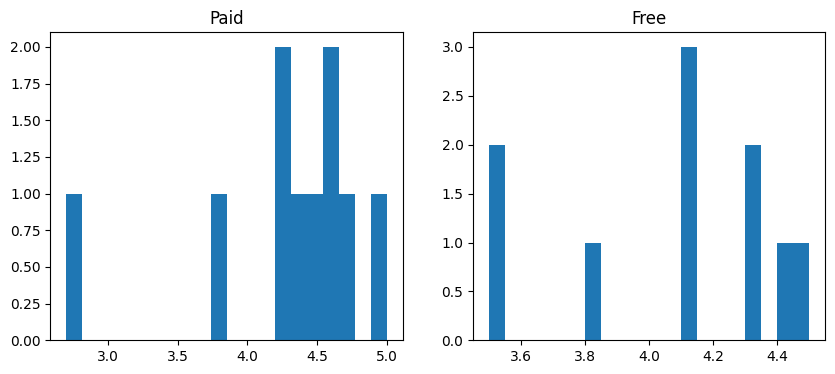

In [7]:
import matplotlib.pyplot as plt

paid = df[df["Type"] == "Paid"]["Rating"]
free = df[df["Type"] == "Free"]["Rating"]

fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=False)
ax[0].hist(paid, bins=20); ax[0].set_title("Paid")
ax[1].hist(free, bins=20); ax[1].set_title("Free")
plt.show()

<h3>Skewness</h3>

In [8]:
print("Skewness Paid:", stats.skew(paid))
print("Skewness Free:", stats.skew(free))

Skewness Paid: -1.5710732923966355
Skewness Free: -0.5744712679187665


negative skew, didominasi rating tinggi

<h3>Uji-t Welch</h3>

In [ ]:
hasil = stats.ttest_ind(paid, free, equal_var=False)

print("t        :", hasil.statistic)
print("df       :", hasil.df) #derajat kebebasan
print("p-value  :", hasil.pvalue)

t        : 0.9506494831608743
df       : 14.010621429191724
p-value  : 0.35789450596806816


<h3>Interval Kepercayaan</h3>

In [11]:
ci = hasil.confidence_interval(confidence_level=0.95)
print("CI 95%:", ci.low, "sampai", ci.high)

CI 95%: -0.27631280799133967 sampai 0.7163128079913428


<h3>Cohen's d</h3>

In [12]:
n1, n2 = len(paid), len(free)
s1, s2 = paid.std(), free.std()
sp = np.sqrt(((n1-1)*s1**2 + (n2-1)*s2**2) / (n1+n2-2))
d = (paid.mean() - free.mean()) / sp
print("Cohen's d:", d)

Cohen's d: 0.42514337342455133


<h3>Keputusan</h3>

In [13]:
alpha = 0.05
print(hasil.pvalue)
if hasil.pvalue < alpha:
    print("Tolak H0")
else:
    print("Gagal tolak H0")

0.35789450596806816
Gagal tolak H0
